<a href="https://colab.research.google.com/github/piaseckazaneta/Python/blob/main/Rodzic_w_Branzy_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Opis projektu

Cel:

Instalacja bibliotek

In [4]:
import pandas as pd
import numpy as np
import matplotlib as plt

In [5]:
pd.set_option('display.max_columns', None)

Wczytanie danych

In [6]:
ogolne = pd.read_csv("0.df_ogolne.csv")
zespol = pd.read_csv("1.df_zespol.csv")
tech = pd.read_csv("2.df_technologie.csv")
projekty = pd.read_csv("3.df_projekty.csv")
org_pracy = pd.read_csv("4.df_organizacja_pracy.csv")
well_being = pd.read_csv("5.df_well_being.csv")
przyszlosc = pd.read_csv("6.df_przyszlosc.csv")

tables = [ogolne, zespol, tech, projekty, org_pracy, well_being, przyszlosc]

In [7]:
# 1. Połączenie tabel (zakładam zgodność indeksów 297 wierszy)
df_rodzic = pd.concat([
    ogolne,
    projekty,
    well_being,
    przyszlosc,
    org_pracy], axis=1)

In [8]:
# 2. Definicja profilu (Płeć x Rodzicielstwo)
conditions = [
    (df_rodzic['płeć'].str.lower().str.contains('kobieta', na=False)) & (df_rodzic['rodzic'] == True),
    (df_rodzic['płeć'].str.lower().str.contains('kobieta', na=False)) & (df_rodzic['rodzic'] == False),
    (df_rodzic['płeć'].str.lower().str.contains('mężczyzn|mezczyzn', na=False)) & (df_rodzic['rodzic'] == True),
    (df_rodzic['płeć'].str.lower().str.contains('mężczyzn|mezczyzn', na=False)) & (df_rodzic['rodzic'] == False)
]
choices = ['Matka', 'Kobieta bez dzieci', 'Ojciec', 'Mężczyzna bez dzieci']

df_rodzic['profil_grupy'] = np.select(conditions, choices, default='Inne/Brak danych')

# Sprawdzenie liczebności grup
print(df_rodzic['profil_grupy'].value_counts())

profil_grupy
Kobieta bez dzieci      122
Mężczyzna bez dzieci     91
Matka                    45
Ojciec                   39
Name: count, dtype: int64


Filar 1: Higiena czasu pracy i ramy dnia

Cel analityczny

Weryfikacja hipotezy: „Czy rodzicielstwo wymusza sztywne trzymanie się 8 godzin pracy kosztem pracy w weekendy, czy może to osoby bez dzieci częściej biorą nadgodziny?”

In [9]:
df_rodzic['ile godzin dziennie średnio pracujesz'].unique()

array(['8 godzin', '9–10 godzin', 'mniej niż 6 godzin', '6–7 godzin', nan,
       'więcej'], dtype=object)

In [10]:
mapa_godzin = {
    '8 godzin': 8,
    '9-10 godzin': 9.5,
    '6-7 godzin': 6.5,
    'mniej niż 6 godzin': 5,
    'nan': np.nan,
    'więcej': 11
}

In [11]:
df_rodzic['godziny_dziennie'] = df_rodzic['ile godzin dziennie średnio pracujesz'].map(mapa_godzin)

In [12]:
df_rodzic.groupby('profil_grupy')['godziny_dziennie'].mean()

,godziny_dziennie
profil_grupy,
Kobieta bez dzieci,7.666667
Matka,7.823529
Mężczyzna bez dzieci,7.820896
Ojciec,7.689655


In [13]:
godziny_summary = (
    pd.crosstab(
        df_rodzic['profil_grupy'],
        df_rodzic['godziny_dziennie'],
        normalize='index'
    ) * 100
).round(1)

nadgodziny_summary = (
    pd.crosstab(
        df_rodzic['profil_grupy'],
        df_rodzic['jak często zdarza ci się pracować po godzinach lub w weekendy'],
        normalize='index'
    ) * 100
).round(1)

In [14]:
godziny_summary

godziny_dziennie,5.0,8.0,11.0
profil_grupy,,,
Kobieta bez dzieci,13.6,84.0,2.5
Matka,5.9,94.1,0.0
Mężczyzna bez dzieci,13.4,79.1,7.5
Ojciec,10.3,89.7,0.0


In [15]:
nadgodziny_summary

jak często zdarza ci się pracować po godzinach lub w weekendy,czasami (kilka razy w miesiącu),nigdy,regularnie (w każdym tygodniu),sporadycznie (raz na kilka miesięcy)
profil_grupy,,,,
Kobieta bez dzieci,28.9,27.3,8.3,35.5
Matka,22.2,31.1,2.2,44.4
Mężczyzna bez dzieci,22.2,22.2,13.3,42.2
Ojciec,13.2,23.7,5.3,57.9


Filar 2: Model pracy – oczekiwania a rzeczywistość

Cel analityczny

Zbadanie luki pomiędzy obecnym modelem pracy a preferencjami pracowników. Kto doświadcza największego tarcia organizacyjnego?

In [18]:
model_pracy = df_rodzic.groupby('profil_grupy')['w jakim modelu pracujesz na co dzień'].value_counts(normalize=True)
print(model_pracy)

profil_grupy          w jakim modelu pracujesz na co dzień
Kobieta bez dzieci    hybrydowo  - większość z domu           0.396694
                      zdalnie                                 0.347107
                      hybrydowo  - większość z biura          0.181818
                      stacjonarnie                            0.074380
Matka                 zdalnie                                 0.377778
                      hybrydowo  - większość z domu           0.288889
                      hybrydowo  - większość z biura          0.244444
                      stacjonarnie                            0.088889
Mężczyzna bez dzieci  zdalnie                                 0.444444
                      hybrydowo  - większość z biura          0.266667
                      hybrydowo  - większość z domu           0.222222
                      stacjonarnie                            0.066667
Ojciec                zdalnie                                 0.342105
                  

In [21]:
model_pracy_cross = (
    pd.crosstab(
        df_rodzic['profil_grupy'],
        df_rodzic['w jakim modelu pracujesz na co dzień'],
        normalize='index'
    ) * 100
).round(1)

print(model_pracy_cross)

w jakim modelu pracujesz na co dzień  hybrydowo  - większość z biura  \
profil_grupy                                                           
Kobieta bez dzieci                                              18.2   
Matka                                                           24.4   
Mężczyzna bez dzieci                                            26.7   
Ojciec                                                          23.7   

w jakim modelu pracujesz na co dzień  hybrydowo  - większość z domu  \
profil_grupy                                                          
Kobieta bez dzieci                                             39.7   
Matka                                                          28.9   
Mężczyzna bez dzieci                                           22.2   
Ojciec                                                         31.6   

w jakim modelu pracujesz na co dzień  stacjonarnie  zdalnie  
profil_grupy                                                 
Kobieta bez dzie

In [19]:
model_pracy = df_rodzic.groupby('profil_grupy')['jak chciał(a)byś pracować na co dzień'].value_counts(normalize=True)
print(model_pracy)

profil_grupy          jak chciał(a)byś pracować na co dzień
Kobieta bez dzieci    hybrydowo  - większość z domu            0.462810
                      zdalnie                                  0.429752
                      hybrydowo  - większość z biura           0.099174
                      stacjonarnie                             0.008264
Matka                 zdalnie                                  0.488889
                      hybrydowo  - większość z domu            0.377778
                      hybrydowo  - większość z biura           0.111111
                      stacjonarnie                             0.022222
Mężczyzna bez dzieci  zdalnie                                  0.488889
                      hybrydowo  - większość z domu            0.433333
                      hybrydowo  - większość z biura           0.077778
Ojciec                hybrydowo  - większość z domu            0.473684
                      zdalnie                                  0.342105
    

In [23]:
df_rodzic['niedopasowanie_modelu'] = (
    df_rodzic['w jakim modelu pracujesz na co dzień'] != df_rodzic['jak chciał(a)byś pracować na co dzień']
)

mismatch_by_group = (
    df_rodzic.groupby('profil_grupy')['niedopasowanie_modelu']
    .agg(odsetek_niedopasowania=lambda x: (x.mean() * 100).round(1), liczba_osob='count')
    .sort_values(by='odsetek_niedopasowania', ascending=False)
)
print(mismatch_by_group)

                      odsetek_niedopasowania  liczba_osob
profil_grupy                                             
Kobieta bez dzieci                      45.1          122
Mężczyzna bez dzieci                    41.8           91
Matka                                   33.3           45
Ojciec                                  33.3           39


In [27]:
# Zobaczmy, jak wygląda ten rozjazd w szczegółach dla każdej grupy
pd.crosstab(
    df_rodzic['profil_grupy'],
    [df_rodzic['w jakim modelu pracujesz na co dzień'], df_rodzic['jak chciał(a)byś pracować na co dzień']],
    rownames=['Profil'],
    colnames=['Obecny', 'Wymarzony']
)

Obecny               hybrydowo  - większość z biura  \
Wymarzony            hybrydowo  - większość z biura   
Profil                                                
Kobieta bez dzieci                                7   
Matka                                             5   
Mężczyzna bez dzieci                              6   
Ojciec                                            3   

Obecny                                                      \
Wymarzony            hybrydowo  - większość z domu zdalnie   
Profil                                                       
Kobieta bez dzieci                               9       6   
Matka                                            4       2   
Mężczyzna bez dzieci                            14       4   
Ojciec                                           4       2   

Obecny                hybrydowo  - większość z domu  \
Wymarzony            hybrydowo  - większość z biura   
Profil                                                
Kobieta bez dzieci                                3   
Matka                                             0   
Mężczyzna bez dzieci                              0   
Ojciec                                            0   

Obecny                                                      \
Wymarzony            hybrydowo  - większość z domu zdalnie   
Profil                                                       
Kobieta bez dzieci                              29      16   
Matka                                            9       4   
Mężczyzna bez dzieci                            14       6   
Ojciec                                          12       0   

Obecny                                 stacjonarnie  \
Wymarzony            hybrydowo  - większość z biura   
Profil                                                
Kobieta bez dzieci                                2   
Matka                                             0   
Mężczyzna bez dzieci                              1   
Ojciec                                            4   

Obecny                                                                   \
Wymarzony            hybrydowo  - większość z domu stacjonarnie zdalnie   
Profil                                                                    
Kobieta bez dzieci                               5            1       0   
Matka                                            2            1       1   
Mężczyzna bez dzieci                             4            0       1   
Ojciec                                           0            0       0   

Obecny                                     zdalnie          
Wymarzony            hybrydowo  - większość z domu zdalnie  
Profil                                                      
Kobieta bez dzieci                              12      30  
Matka                                            2      15  
Mężczyzna bez dzieci                             7      33  
Ojciec                                           2      11

Filar 3: Dojrzałość projektowa – pożary ad-hoc i brak zastępstwa

Cel analityczny

Sprawdzenie stopnia ryzyka operacyjnego: czy zespoły zapewniają backup w projektach na wypadek nagłej nieobecności (np. zwolnienia lekarskiego na dziecko) i jak często pracownicy są wybijani z rytmu zadaniami doraźnymi?

In [34]:
backup_summary = (
    pd.crosstab(
        df_rodzic['profil_grupy'],
        df_rodzic['czy masz w swoich projektach "backup", czyli osoby, które są zaznajomione z twoimi projektami i mogłyby cię zastąpić w razie nieobecności'],
        normalize='index'
    ) * 100
).round(1)

adhoc_summary = (
    pd.crosstab(
        df_rodzic['profil_grupy'],
        df_rodzic['jak często realizujesz zadania ad hoc (jednorazowe, nieplanowane zapytania, np. szybkie analizy na potrzeby biznesu)'],
        normalize='index'
    ) * 100
).round(1)

In [35]:
print(backup_summary)

czy masz w swoich projektach "backup", czyli osoby, które są zaznajomione z twoimi projektami i mogłyby cię zastąpić w razie nieobecności  częściowo – ktoś ma ogólną wiedzę, ale nie zna szczegółów  \
profil_grupy                                                                                                                                                                                           
Kobieta bez dzieci                                                                                                                                                                      49.2           
Matka                                                                                                                                                                                   53.3           
Mężczyzna bez dzieci                                                                                                                                                                    53.8           


In [36]:
print(adhoc_summary)

jak często realizujesz zadania ad hoc (jednorazowe, nieplanowane zapytania, np. szybkie analizy na potrzeby biznesu)  bardzo często, to większość mojej pracy  \
profil_grupy                                                                                                                                                    
Kobieta bez dzieci                                                                                                                                        7.4   
Matka                                                                                                                                                    15.6   
Mężczyzna bez dzieci                                                                                                                                      9.9   
Ojciec                                                                                                                                                   25.6   

jak często realizujesz zadania ad

Filar 4: Przestrzeń na rozwój i perspektywy

Cel analityczny

Odpowiedź na kluczowe pytanie o rozwój kompetencyjny: czy obciążenie domowe i zawodowe hamuje podnoszenie kwalifikacji w dynamicznie zmieniającej się branży?

In [37]:
rozwoj_summary = (
    pd.crosstab(
        df_rodzic['profil_grupy'],
        df_rodzic['czy obecnie szkolisz się lub rozwijasz swoje umiejętności zawodowe'],
        normalize='index'
    ) * 100
).round(1)

In [38]:
print(rozwoj_summary)

czy obecnie szkolisz się lub rozwijasz swoje umiejętności zawodowe  nie, ale planuję w najbliższym czasie  \
profil_grupy                                                                                                
Kobieta bez dzieci                                                                                   12.3   
Matka                                                                                                 6.7   
Mężczyzna bez dzieci                                                                                  8.9   
Ojciec                                                                                                2.6   

czy obecnie szkolisz się lub rozwijasz swoje umiejętności zawodowe  nie, na ten moment skupiam się na innych aspektach życia  \
profil_grupy                                                                                                                   
Kobieta bez dzieci                                                                       

In [40]:
import matplotlib.pyplot as plt

# Konfiguracja stylu wykresów (minimalistyczny, profesjonalny styl)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#e0e0e0'
plt.rcParams['axes.linewidth'] = 0.8

kolory_profili = {
    'Matka': '#e06666',               # akcent koralowy
    'Ojciec': '#6fa8dc',              # błękitny
    'Kobieta bez dzieci': '#b6d7a8',  # stonowana zieleń
    'Mężczyzna bez dzieci': '#ffd966' # stonowany żółty
}

def rysuj_wykres_filaru(seria_danych, tytul, podtytul, jednostka='%'):
    """
    Funkcja generuje czytelny, poziomy wykres słupkowy z bezpośrednimi etykietami.
    """
    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)

    # Sortujemy, żeby najwyższa lub najważniejsza wartość była czytelna
    dane = seria_danych.sort_values(ascending=True)

    # Dobieramy kolory na podstawie profili
    kolory = [kolory_profili.get(k, '#4a90e2') for k in dane.index]

    bars = ax.barh(dane.index, dane.values, color=kolory, height=0.55)

    # Dodajemy bezpośrednie etykiety z wartościami na końcu każdego słupka
    max_val = dane.values.max() if len(dane) > 0 else 100
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (max_val * 0.02),
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}{jednostka}",
            va='center',
            ha='left',
            fontsize=10,
            fontweight='bold',
            color='#333333'
        )

    # Czyszczenie obramowania (Tufte style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')

    ax.xaxis.set_visible(False) # usuwamy oś X, bo wartości są na słupkach
    ax.tick_params(axis='y', labelsize=10)

    # Nagłówek i podtytuł
    plt.title(tytul, fontsize=12, fontweight='bold', pad=22, loc='left', color='#1a1a1a')
    plt.suptitle(podtytul, fontsize=9, x=0.125, y=0.93, ha='left', color='#666666')

    plt.tight_layout()
    plt.show()

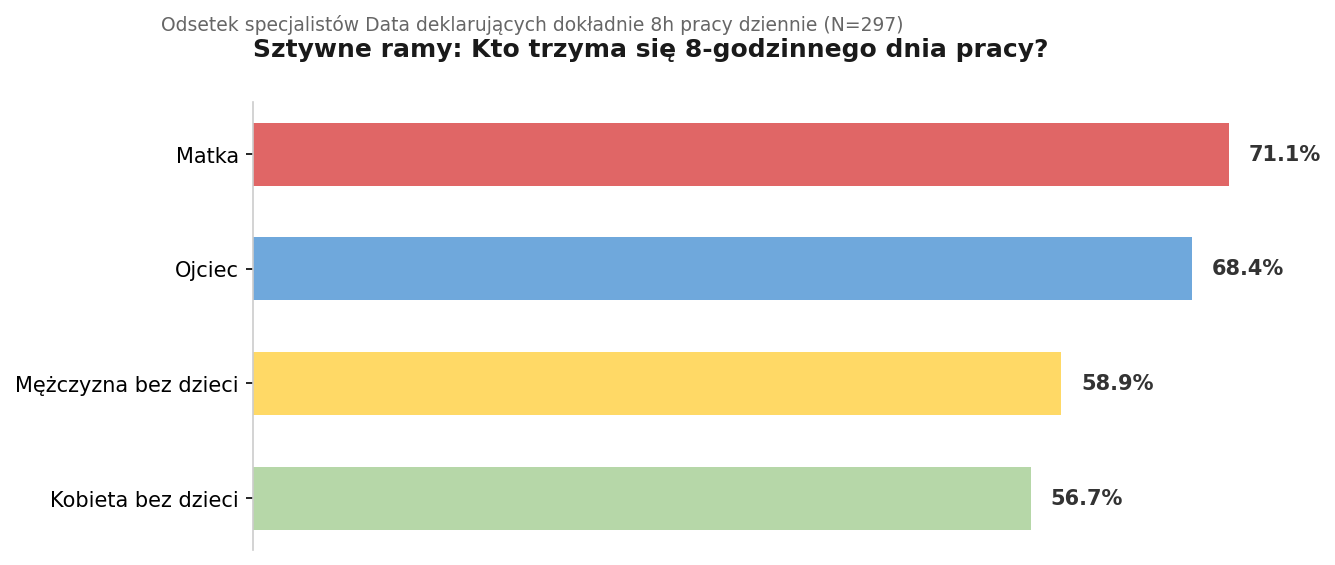

In [42]:
# Odsetek osób, które pracują dokładnie 8h dziennie
sztywne_8h = (
    pd.crosstab(df_rodzic['profil_grupy'], df_rodzic['ile godzin dziennie średnio pracujesz'], normalize='index')['8 godzin'] * 100
).round(1)

rysuj_wykres_filaru(
    sztywne_8h,
    tytul="Sztywne ramy: Kto trzyma się 8-godzinnego dnia pracy?",
    podtytul="Odsetek specjalistów Data deklarujących dokładnie 8h pracy dziennie (N=297)"
)